# Water Tank Monitoring: Predicting Remaining Water with Linear Regression

**Goal:** predict remaining water (liters) from time, measured water level, and water usage rate.




## 1. Import libraries

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split


## 2. Load the dataset
Run this cell and upload `water_tank_dataset_time_level_usage.csv` when prompted.

In [7]:
df = pd.read_csv('/content/water_tank_dataset_time_level_usage.csv')
print('First five records:')
display(df.head())

print('\nLast five records:')
display(df.tail())

First five records:


,time,water_level_percent,usage_rate_liters_per_min,remaining_water_liters
0,1/1/2026 0:00,93.79,2.50,937.94
1,1/1/2026 0:05,92.55,2.23,925.48
2,1/1/2026 0:10,91.38,2.05,913.76
3,1/1/2026 0:15,90.30,2.56,902.97
4,1/1/2026 0:20,89.20,2.01,892.00



Last five records:


,time,water_level_percent,usage_rate_liters_per_min,remaining_water_liters
995,1/4/2026 10:55,0.0,2.60,0.0
996,1/4/2026 11:00,0.0,1.83,0.0
997,1/4/2026 11:05,0.0,1.24,0.0
998,1/4/2026 11:10,0.0,2.13,0.0
999,1/4/2026 11:15,0.0,2.33,0.0


## 3. Inspect and prepare data

In [9]:
print('Dataset shape:', df.shape)
display(df.info())
display(df.describe())
print('Missing values per column:\n', df.isna().sum())

# Convert time column to datetime objects first
df['time'] = pd.to_datetime(df['time'])

df = df.dropna().sort_values('time').reset_index(drop=True)
# Convert timestamps into numeric minutes since the first reading.
df['elapsed_minutes'] = (df['time'] - df['time'].min()).dt.total_seconds() / 60
df.head()

Dataset shape: (1000, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   time                       1000 non-null   object 
 1   water_level_percent        1000 non-null   float64
 2   usage_rate_liters_per_min  1000 non-null   float64
 3   remaining_water_liters     1000 non-null   float64
dtypes: float64(3), object(1)
memory usage: 31.4+ KB


None

,water_level_percent,usage_rate_liters_per_min,remaining_water_liters
count,1000.000000,1000.000000,1000.000000
mean,3.933210,2.469890,39.332040
std,15.301479,0.974619,153.014091
min,0.000000,0.000000,0.000000
25%,0.000000,1.807500,0.000000
50%,0.000000,2.445000,0.000000
75%,0.000000,3.162500,0.000000
max,93.790000,5.490000,937.940000


Missing values per column:
 time                         0
water_level_percent          0
usage_rate_liters_per_min    0
remaining_water_liters       0
dtype: int64


,time,water_level_percent,usage_rate_liters_per_min,remaining_water_liters,elapsed_minutes
0,2026-01-01 00:00:00,93.79,2.50,937.94,0.0
1,2026-01-01 00:05:00,92.55,2.23,925.48,5.0
2,2026-01-01 00:10:00,91.38,2.05,913.76,10.0
3,2026-01-01 00:15:00,90.30,2.56,902.97,15.0
4,2026-01-01 00:20:00,89.20,2.01,892.00,20.0


## 4. Choose features and target
The target is `remaining_water_liters`. We use elapsed time, measured water level, and usage rate as inputs.


In [10]:
feature_columns = ['elapsed_minutes', 'water_level_percent', 'usage_rate_liters_per_min']
target_column = 'remaining_water_liters'
X = df[feature_columns]
y = df[target_column]

# Chronological split: earlier observations train the model; later observations test it.
split_index = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]
print('Training rows:', len(X_train), '| Testing rows:', len(X_test))


Training rows: 800 | Testing rows: 200


## 5. Train Linear Regression

In [11]:
model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print('Model trained successfully.')
print('Intercept:', model.intercept_)
print('Coefficients:')
for name, coefficient in zip(feature_columns, model.coef_):
    print(f'  {name}: {coefficient:.4f}')


Model trained successfully.
Intercept: 0.0006267458521236335
Coefficients:
  elapsed_minutes: -0.0000
  water_level_percent: 9.9999
  usage_rate_liters_per_min: 0.0001


## 6. Evaluate model performance
MAE and RMSE are in liters. R² measures how well the model explains variation in the test data.

In [12]:
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)
print(f'MAE:  {mae:.2f} liters')
print(f'RMSE: {rmse:.2f} liters')
print(f'R²:   {r2:.4f}')


MAE:  0.00 liters
RMSE: 0.00 liters
R²:   1.0000


## 7. Plot actual vs predicted water remaining

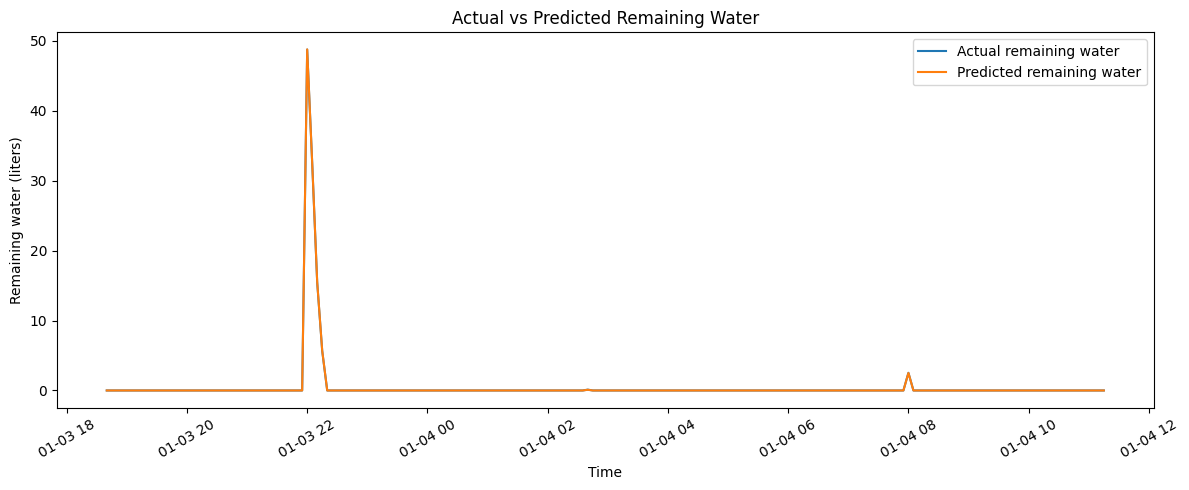

In [13]:
plt.figure(figsize=(12, 5))
plt.plot(df['time'].iloc[split_index:], y_test.to_numpy(), label='Actual remaining water')
plt.plot(df['time'].iloc[split_index:], predictions, label='Predicted remaining water')
plt.xlabel('Time')
plt.ylabel('Remaining water (liters)')
plt.title('Actual vs Predicted Remaining Water')
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()


## 8. Try a new prediction
Edit the values below to estimate remaining water. `elapsed_minutes` is minutes after the first dataset timestamp.

In [14]:
new_reading = pd.DataFrame([{
    'elapsed_minutes': 2500,
    'water_level_percent': 45.0,
    'usage_rate_liters_per_min': 2.1
}])
estimated_liters = model.predict(new_reading[feature_columns])[0]
print(f'Estimated remaining water: {estimated_liters:.2f} liters')
print(f'Estimated tank level: {estimated_liters / 1000 * 100:.1f}% (assuming a 1000 L tank)')


Estimated remaining water: 450.00 liters
Estimated tank level: 45.0% (assuming a 1000 L tank)
